In [13]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

sns.set_theme(style='whitegrid')

In [14]:
df = pd.read_csv('Online Retail.csv', encoding='ISO-8859-1')

print(df.shape)
df.info()

df.head()

(541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.5500,17850.0000,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.3900,17850.0000,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.7500,17850.0000,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.3900,17850.0000,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.3900,17850.0000,United Kingdom


In [15]:
rows_before = len(df)
invoices_before = df['InvoiceNo'].nunique()

df_clean = df.dropna(subset=['Description']).copy()
df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str)
df_clean = df_clean[~df_clean['InvoiceNo'].str.startswith('C')]
df_clean = df_clean[df_clean['Quantity'] > 0]

rows_after = len(df_clean)
invoices_after = df_clean['InvoiceNo'].nunique()

summary_clean = pd.DataFrame({
    'Metrik': ['Jumlah Baris Data', 'Jumlah Unique Invoice'],
    'Sebelum Pembersihan': [rows_before, invoices_before],
    'Setelah Pembersihan': [rows_after, invoices_after],
    'Selisih Dihapus': [rows_before - rows_after, invoices_before - invoices_after]
})

summary_clean

,Metrik,Sebelum Pembersihan,Setelah Pembersihan,Selisih Dihapus
0,Jumlah Baris Data,541909,530693,11216
1,Jumlah Unique Invoice,25900,20136,5764


In [16]:
basket = (df_clean.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket_sets = (basket > 0).astype(bool)
basket_sets.head()

Description   4 PURPLE FLOCK DINNER CANDLES   50'S CHRISTMAS GIFT BAG LARGE  \
InvoiceNo                                                                     
536365                                False                           False   
536366                                False                           False   
536367                                False                           False   
536368                                False                           False   
536369                                False                           False   

Description   DOLLY GIRL BEAKER   I LOVE LONDON MINI BACKPACK  \
InvoiceNo                                                       
536365                    False                         False   
536366                    False                         False   
536367                    False                         False   
536368                    False                         False   
536369                    False                         False   

Description   I LOVE LONDON MINI RUCKSACK   NINE DRAWER OFFICE TIDY  \
InvoiceNo                                                             
536365                              False                     False   
536366                              False                     False   
536367                              False                     False   
536368                              False                     False   
536369                              False                     False   

Description   OVAL WALL MIRROR DIAMANTE    RED SPOT GIFT BAG LARGE  \
InvoiceNo                                                            
536365                             False                     False   
536366                             False                     False   
536367                             False                     False   
536368                             False                     False   
536369                             False                     False   

Description   SET 2 TEA TOWELS I LOVE LONDON    SPACEBOY BABY GIFT SET  \
InvoiceNo                                                                
536365                                  False                    False   
536366                                  False                    False   
536367                                  False                    False   
536368                                  False                    False   
536369                                  False                    False   

Description   TOADSTOOL BEDSIDE LIGHT    TRELLIS COAT RACK  \
InvoiceNo                                                    
536365                           False               False   
536366                           False               False   
536367                           False               False   
536368                           False               False   
536369                           False               False   

Description  *Boombox Ipod Classic  *USB Office Mirror Ball  \
InvoiceNo                                                     
536365                       False                    False   
536366                       False                    False   
536367                       False                    False   
536368                       False                    False   
536369                       False                    False   

Description  10 COLOUR SPACEBOY PEN  12 COLOURED PARTY BALLOONS  \
InvoiceNo                                                         
536365                        False                       False   
536366                        False                       False   
536367                        False                       False   
536368                        False                       False   
536369                        False                       False   

Description  12 DAISY PEGS IN WOOD BOX  12 EGG HOUSE PAINTED WOOD  \
InvoiceNo                                                         

In [17]:
frequent_itemsets = fpgrowth(basket_sets, min_support=0.01, use_colnames=True)

rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)

rules_sorted = rules.sort_values('lift', ascending=False).reset_index(drop=True)

rules_sorted[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10)

,antecedents,consequents,support,confidence,lift
0,frozenset({HERB MARKER THYME}),"frozenset({HERB MARKER ROSEMARY, HERB MARKER P...",0.0101,0.8565,80.2200
1,"frozenset({HERB MARKER ROSEMARY, HERB MARKER P...",frozenset({HERB MARKER THYME}),0.0101,0.9442,80.2200
2,frozenset({HERB MARKER ROSEMARY}),"frozenset({HERB MARKER THYME, HERB MARKER PARS...",0.0101,0.8458,79.9610
3,"frozenset({HERB MARKER THYME, HERB MARKER PARS...",frozenset({HERB MARKER ROSEMARY}),0.0101,0.9531,79.9610
4,frozenset({HERB MARKER THYME}),frozenset({HERB MARKER ROSEMARY}),0.0110,0.9325,78.2359
5,frozenset({HERB MARKER ROSEMARY}),frozenset({HERB MARKER THYME}),0.0110,0.9208,78.2359
6,frozenset({HERB MARKER PARSLEY}),"frozenset({HERB MARKER ROSEMARY, HERB MARKER T...",0.0101,0.8529,77.7141
7,"frozenset({HERB MARKER ROSEMARY, HERB MARKER T...",frozenset({HERB MARKER PARSLEY}),0.0101,0.9186,77.7141
8,frozenset({HERB MARKER THYME}),frozenset({HERB MARKER PARSLEY}),0.0106,0.8987,76.0374
9,frozenset({HERB MARKER PARSLEY}),frozenset({HERB MARKER THYME}),0.0106,0.8950,76.0374


In [18]:
top3_rules = rules_sorted.head(3).copy()

for idx, row in top3_rules.iterrows():
    ant = list(row['antecedents'])
    cons = list(row['consequents'])
    print(f"Aturan {idx + 1}: {ant} -> {cons}")
    print(f"Support: {row['support']:.4f} | Confidence: {row['confidence']:.4f} | Lift: {row['lift']:.4f}\n")

Aturan 1: ['HERB MARKER THYME'] -> ['HERB MARKER ROSEMARY', 'HERB MARKER PARSLEY']
Support: 0.0101 | Confidence: 0.8565 | Lift: 80.2200

Aturan 2: ['HERB MARKER ROSEMARY', 'HERB MARKER PARSLEY'] -> ['HERB MARKER THYME']
Support: 0.0101 | Confidence: 0.9442 | Lift: 80.2200

Aturan 3: ['HERB MARKER ROSEMARY'] -> ['HERB MARKER THYME', 'HERB MARKER PARSLEY']
Support: 0.0101 | Confidence: 0.8458 | Lift: 79.9610



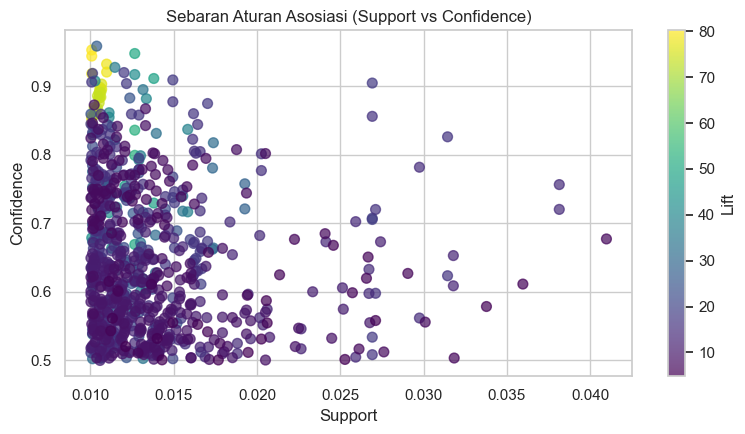

In [19]:
plt.figure(figsize=(8, 4.5))
scatter = plt.scatter(rules_sorted['support'], rules_sorted['confidence'], c=rules_sorted['lift'], cmap='viridis', alpha=0.7, s=50)
plt.colorbar(scatter, label='Lift')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.title('Sebaran Aturan Asosiasi (Support vs Confidence)')
plt.tight_layout()
plt.savefig('scatter_rules.png', dpi=300)
plt.show()

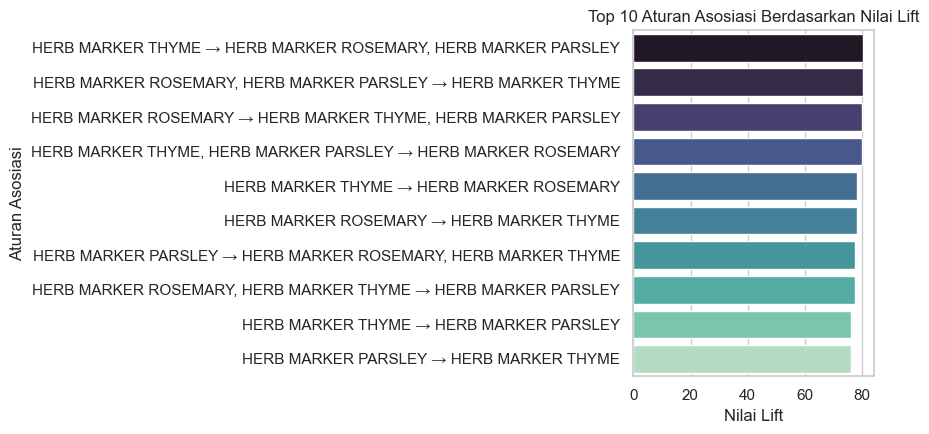

In [20]:
top10_rules = rules_sorted.head(10).copy()
top10_rules['rule_label'] = top10_rules.apply(
    lambda row: f"{', '.join(list(row['antecedents']))} → {', '.join(list(row['consequents']))}", axis=1
)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=top10_rules, x='lift', y='rule_label', hue='rule_label', palette='mako')
plt.legend([], [], frameon=False)
plt.xlabel('Nilai Lift')
plt.ylabel('Aturan Asosiasi')
plt.title('Top 10 Aturan Asosiasi Berdasarkan Nilai Lift')
plt.tight_layout()
plt.savefig('bar_top10_lift.png', dpi=300)
plt.show()